# Multi-Task Contextual Decision-Making (Yang19 Cognitive Tasks)

This environment implements a suite of 20 context-dependent cognitive tasks inspired by the work of [Yang et al. (2019)](https://pubmed.ncbi.nlm.nih.gov/30643294/#:~:text=The%20brain%20has%20the%20ability,task%20representations%2C%20a%20critical%20feature). In these tasks, the agent must flexibly switch between different context rules on each trial, similar in spirit to the classic [context-dependent decision-making](https://neurogym.github.io/neurogym/latest/api/envs/#neurogym.envs.native.contextdecisionmaking.ContextDecisionMaking) experiment of [Mante et al. (2013)](https://www.nature.com/articles/nature12742). The key features of this multi-task environment are:

1. **Two-Choice Outputs** (`dim_ring=2`): All tasks share a common action space represented as positions on a ring. With `dim_ring = 2`, there are two choice outputs located at 0° and 180° on this ring (interpreted as "left" and "right" choices, respectively). The agent's goal on each trial is to select the correct one of these two outputs.
2. **Stimulus Inputs with Modality-Specific Evidence**: Each task provides sensory evidence (stimuli) that may come from one or two modalities. The stimuli are often encoded via a cosine-tuned input bump centered on one of the choice positions, with its amplitude representing the evidence strength. For example, a stimulus favoring the left choice might produce an activity peak at 0° on the input ring.
3. **Randomized Ground-Truth Choices**: The correct choice (ground truth) is randomized on each trial (for two choices: left or right). This means on some trials left is the correct answer, and on others right is correct, preventing the agent from biasing toward one action.
4. **Variable Difficulty Evidence**: The strength of the stimulus evidence (e.g., coherence level in a motion stimulus) is also randomly sampled each trial. Sometimes the evidence strongly favors one choice, and other times it is weak or ambiguous.

This collection of 20 tasks exercises various cognitive skills, including working memory (e.g., remembering stimuli across a delay in matching tasks), perceptual decision-making (integrating noisy sensory evidence over time), rule-based categorization, and inhibitory control (suppressing or initiating actions under certain rules). All tasks are implemented in a consistent format so that a single neural network agent can learn them together via supervised training.

In this notebook, we will:

1. Train an agent on the 20-task suite using supervised learning. We will generate trial data from the environment and train a recurrent neural network to predict the correct choices.
2. Evaluate the agent's performance and behavior across tasks. After training, we will examine how well the agent learned each of the 20 tasks and whether it can flexibly switch contexts from trial to trial.


# 0. Install Dependencies

To begin, install the `neurogym` package. This will automatically install all required dependencies, including Stable-Baselines3.

For detailed instructions on how to install `neurogym` within a conda environment or in editable mode, refer to the [installation instructions](https://github.com/neurogym/neurogym?tab=readme-ov-file#installation).


In [1]:
# Uncomment to install
# ! pip install neurogym[rl]

# 1. Training an Agent on Yang19 Cognitive Tasks


## 1.1 Environment Setup and Initial Agent Behavior

Let's begin by creating and exploring the environment using the `yang19` collection of tasks from NeuroGym. We’ll use the default configuration for all parameters except `dim_ring`, which we set to 2 in order to represent two alternative choices (left/right) arranged on a ring.

To get a sense of the environment dynamics, we’ll visualize a couple of representative tasks (`dm1` and `multidm`) to better understand their structure and how the agent is expected to interact with them.


### 1.1.1 Import Libraries


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F
from IPython.display import clear_output
warnings.filterwarnings("ignore")
clear_output()

### 1.1.2 Environment Setup


In [3]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation

rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation

Trial timing (in milliseconds):
{'fixation': ('uniform', (200, 500)), 'stimulus': ('choice', [200, 400, 600]), 'decision': 200}

Observation space structure:
Box(-inf, inf, (5,), float32)

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': range(1, 3)}


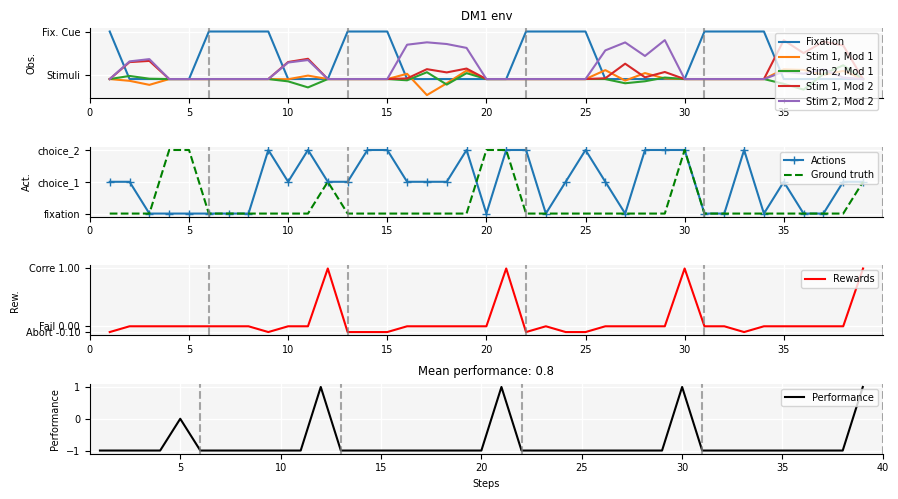

In [4]:
### dm1
timing = {
    "fixation": ("uniform", (200, 500)),
    "stimulus": ("choice", [200, 400, 600]),
    "decision": 200,
}
kwargs = {
    "dt": dt,
    "dim_ring": dim_ring,
    "rewards": rewards,
    "timing": timing,
    "sigma": sigma,
}
task = "dm2"
task = f"yang19.{task}-v0"
env_dm = ngym.make(task, **kwargs)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env_dm.timing)

print("\nObservation space structure:")
print(env_dm.observation_space)

print("\nAction space structure:")
print(env_dm.action_space)
print("Action mapping:")
print(env_dm.action_space.name)

obs, info = env_dm.reset()

stim1 = [f'Stim {i}, Mod 1' for i in range(1, kwargs['dim_ring'] + 1)]
stim2 = [f'Stim {i}, Mod 2' for i in range(1, kwargs['dim_ring'] + 1)]

# Visualize example trials
fig = plot_env(
    env_dm,
    name='DM1',
    ob_traces=['Fixation'] + stim1 + stim2,
    num_trials=5,
    plot_performance=True,
    fig_kwargs={'figsize': (9, 5)},
)

Trial timing (in milliseconds):
{'fixation': ('uniform', (200, 500)), 'sample': 500, 'delay': 1000, 'test': 500, 'decision': 200, 'stimulus': 500}

Observation space structure:
Box(-inf, inf, (5,), float32)

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': range(1, 3)}


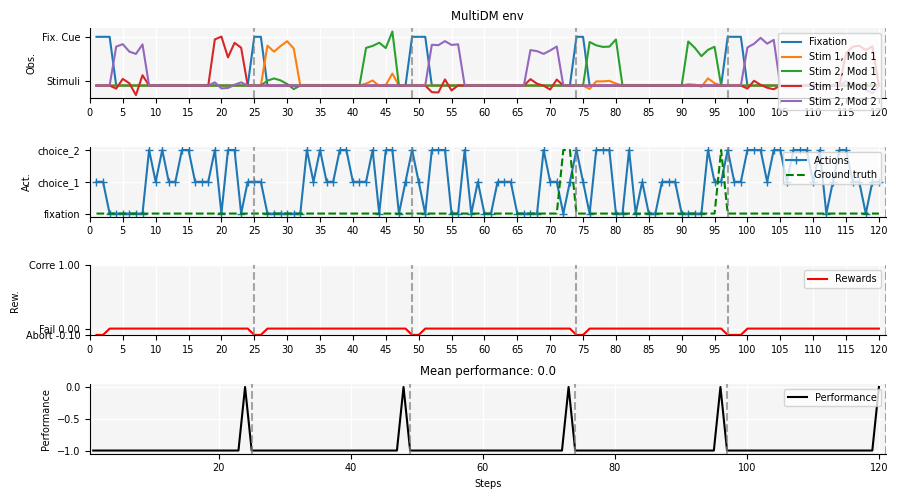

In [5]:
### multidm
timing = {
    "fixation": ("uniform", (200, 500)),
    "stimulus": 500,
    "decision": 200,
}
kwargs = {
    "dt": dt,
    "dim_ring": dim_ring,
    "rewards": rewards,
    "timing": timing,
    "sigma": sigma,
}
task = "dms"
task = f"yang19.{task}-v0"
env_multidm = ngym.make(task, **kwargs)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env_multidm.timing)

print("\nObservation space structure:")
print(env_multidm.observation_space)

print("\nAction space structure:")
print(env_multidm.action_space)
print("Action mapping:")
print(env_multidm.action_space.name)

obs, info = env_multidm.reset()

stim1 = [f'Stim {i}, Mod 1' for i in range(1, kwargs['dim_ring'] + 1)]
stim2 = [f'Stim {i}, Mod 2' for i in range(1, kwargs['dim_ring'] + 1)]

# Visualize example trials
fig = plot_env(
    env_multidm,
    name='MultiDM',
    ob_traces=['Fixation'] + stim1 + stim2,
    num_trials=5,
    plot_performance=True,
    fig_kwargs={'figsize': (9, 5)},
)

We wrap the `yang19` environments using NeuroGym’s `ScheduleEnvs` wrapper, which allows us to interleave multiple tasks into a single training loop. Each cognitive task is instantiated as a separate environment, and a scheduling policy (`RandomSchedule`) determines which task is sampled on each trial. When `env_input=True`, a one-hot vector is appended to the observation to indicate the currently active task, allowing the agent to learn task-specific behavior within a unified architecture.


In [6]:
kwargs = {'dt': dt, 'dim_ring': dim_ring}
seq_len = 100

# Make supervised dataset
tasks = get_collection('yang19')
envs = [ngym.make(task, **kwargs) for task in tasks]
schedule = RandomSchedule(len(envs))
# schedule = SequentialSchedule(len(envs))
env = ScheduleEnvs(envs, schedule=schedule, env_input=True)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env.timing)

print("\nObservation space structure:")
print(env.observation_space)

print("\nAction space structure:")
print(env.action_space)
print("Action mapping:")
print(env.action_space.name)

Trial timing (in milliseconds):
{'fixation': 500, 'stimulus': 500, 'delay': 0, 'decision': 500}

Observation space structure:
Box(-inf, inf, (25,), float32)

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': range(1, 3)}


### 1.1.3 Random Agent Behavior

Let's now plot the behavior of a random agent on the task. The agent will randomly choose between the two options (left/right, blue line), and we will visualize its behavior over 5 trials. We will also plot the reward received by the agent at each time step, as well as the performance on each trial. Note that performance is only defined at the end of a trial: it is 1 if the agent made the correct choice, and 0 otherwise.


In [7]:
obs, info = env.reset()

# Visualize example trials
# fig = plot_env(
#     env,
#     name='Yang et al.',
#     ob_traces=None,
#     num_trials=5,
#     plot_performance=True,
#     fig_kwargs={'figsize': (9, 5)},
# )

# Evaluate performance of random policy
eval_monitor = Monitor(env)
print("\nEvaluating random policy performance...")
metrics = eval_monitor.evaluate_policy(num_trials=EVAL_TRIALS)
print(f"\nRandom policy metrics ({EVAL_TRIALS:,} trials):")
print(f"Mean performance: {metrics['mean_performance']:.4f}")
print(f"Mean reward: {metrics['mean_reward']:.4f}")


Evaluating random policy performance...

Random policy metrics (100 trials):
Mean performance: 0.4800
Mean reward: 0.4800


# 2. Learning the Task as a Supervised Problem

We will now train the agent using supervised learning. NeuroGym provides functionality to generate a dataset directly from the environment, allowing us to sample batches of inputs and corresponding labels for training.


## 2.1 Converting the Environment to a Supervised Dataset


### 2.1.1 Dataset Setup


In [8]:
seq_len = 100
print(f"Using sequence length: {seq_len}")

# Make supervised dataset
batch_size = 32
print(f"Creating dataset with batch_size={batch_size}")
dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

env = dataset.env

# Extract dimensions
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n
# 20 observations for one-hot encoding of the 20 environments, 1 for fixation,
# 2 for each modality (2 modalities, 4 observations total), for a total of 25 observations
print(f"Observation size: {ob_size}")
print(f"Action size: {act_size}")

# Get a batch of data
# inputs, target = dataset()
# print(f"Input batch shape: {inputs.shape}")
# print(f"Target batch shape: {target.shape}")
# print(inputs[90])

# Set device
device = 'cuda'
print(f"Using device: {device}")

Using sequence length: 100
Creating dataset with batch_size=32
Observation size: 25
Action size: 3
Using device: cuda


## 2.2 Training and Evaluating a Neural Network Model


### 2.2.1 Training the Model


In [9]:
# This setting is low to speed up testing, we recommend setting it to at least 1000
from net.dann import DANN
def train(net, epochs=2000, lyapunov_every=100, lr=1e-3, wd=1e-5):
    seq_len = 100
    batch_size = 16
    dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

    net.train()
    # This weighting deprioritizes class 0 while keeping the other 16 classes equally important,
    # aligning with the reward distribution idea from the RL setting
    class_weights = torch.tensor([0.05] + [1.0]*(act_size - 1)).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # Training loop
    loss_history = []
    loss_log = np.zeros((epochs, 3))
    gradient_log = np.zeros((epochs, 1))
    spectral_radius_log = np.zeros((epochs, 1))
    rec_balance_log = np.zeros((epochs, seq_len))  # Track input balance
    n_lyapunov = epochs // lyapunov_every
    lyapunov_spectrum_log = np.zeros((n_lyapunov, net.hidden_size))  # Track Lyapunov spectrum
    np.set_printoptions(threshold=np.inf)

    for i in range(epochs):
        # Get a batch of data
        inputs, targets = dataset()
        # print(inputs[..., -20:].argmax(axis=-1))
        # Convert to PyTorch tensors
        inputs = torch.from_numpy(inputs).float().to(device)
        targets = torch.from_numpy(targets).long().to(device)

        # Initialize hidden state
        # hidden = sl_model.init_hidden(inputs.size(1), device)



        # Forward pass with hidden state tracking
        outputs, eimask_logit, hidden = net(inputs)

        # Reshape for CrossEntropyLoss
        outputs_flat = outputs.reshape(-1, outputs.size(2))
        targets_flat = targets.reshape(-1)

        # Calculate loss
        # Weight the loss to account for class imbalance (very low weight to 0s, higher weights to 1s and 2s)
        decoding_loss = criterion(outputs_flat, targets_flat)


        if net.entropy_loss:
            # eimask_prob = F.softmax(eimask_logit, dim=-1)
            # eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            # entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
            entropy_loss = net.get_ei_entropy_loss()
            loss_log[i, 2] = entropy_loss.item()
        else:
            entropy_loss = 0.0


        if isinstance(net, SimpleNet):
            l1_loss = net.lstm.Wrec_free.abs().mean()
        else:
            l1_loss = 0

        loss = 1 * entropy_loss + decoding_loss + l1_loss * 0

        # Backward pass and optimize
        loss.backward()
        gradient_log[i, 0] = net.lstm.Wrec_free.grad.norm(2).item()
        if isinstance(net, DANN):
            net.update()
            net.zero_grad()
        else:
            optimizer.step()
            # Zero gradients
            optimizer.zero_grad()

        # Log spectral radius
        weight = net.get_actual_weight()
        spectral_radius = torch.linalg.eigvals(weight).abs().max().item()
        spectral_radius_log[i, 0] = spectral_radius

        rec_balance_log[i] = hidden[-1].detach().cpu().numpy()

        # print statistics
        loss_history.append(loss.item())
        loss_log[i, 0] = loss.item()
        loss_log[i, 1] = decoding_loss.item()
        if i % lyapunov_every == 0:
            print('Epoch [{}/{}], Loss: {:.4f}'.format(i, epochs, loss.item()))
            # Calculate Lyapunov spectrum
            lyapunov_spectrum, _ = net.compute_lyapunov_spectrum(inputs)
            lyapunov_spectrum_log[i // lyapunov_every] = lyapunov_spectrum.detach().cpu().numpy()


    print('Finished Training')
    return net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyapunov_spectrum_log
    # Plot the loss curve
    # plt.figure(figsize=(8, 4))
    # plt.plot(loss_history)
    # plt.title('Training Loss')
    # plt.xlabel('Iterations')
    # plt.ylabel('Loss (50-iteration moving average)')
    # plt.grid(True, alpha=0.3)
    # plt.savefig('./output/multitask/yang19_loss_curve.png')
    # plt.show()

### 2.2.2 Evaluate the Model's Performance


In [10]:
def test(net):
    verbose = False
    # Evaluate performance of the trained model
    net.eval()
    # Initialize storage for each environment
    sl_mean_performance = {}
    for e_i in env.envs:
        sl_mean_performance[e_i.spec.id] = []

    # Evaluate for specified number of trials
    print(f"Evaluating model performance across {EVAL_TRIALS} trials...\n")

    for env_idx, e_i in enumerate(env.envs):
        data = {"action": [], "gt": [], "trial": []}
        total_correct = 0
        for trial_idx in range(EVAL_TRIALS):
            trial = e_i.new_trial()
            data["trial"].append(trial)
            ob, gt = e_i.ob, e_i.gt
            data["gt"].append(gt[-1])
            trial_length = ob.shape[0]

            # Add one-hot encoding for the environment
            env_one_hot = np.zeros((trial_length, len(env.envs)))
            env_one_hot[:, env_idx] = 1.0  # Set the current environment index to 1

            # Concatenate original observation with one-hot encoding
            ob_with_env = np.concatenate([ob, env_one_hot], axis=1)

            ob_with_env = ob_with_env[:, np.newaxis, :]  # Add batch dimension

            inputs = torch.from_numpy(ob_with_env).float().to(device)
            # hidden = sl_model.init_hidden(1, device)

            with torch.no_grad():
                outputs, _, hidden = net(inputs)
                pred_actions = torch.argmax(outputs, dim=2)
                data["action"].append(pred_actions[-1, 0].cpu().numpy())

            decision_idx = trial_length - 1
            is_correct = (gt[decision_idx] == pred_actions[decision_idx, 0].cpu().numpy())
            total_correct += is_correct

        accuracy = total_correct / EVAL_TRIALS
        sl_mean_performance[e_i.spec.id].append(accuracy)
        for key in data:
            if key != "trial":
                data[key] = np.array(data[key])


    # Print average performance
    print("Average performance across all environments:")
    mean_acc_all = np.array([np.mean(sl_mean_performance[e_i.spec.id]) for e_i in env.envs])
    for e_i in env.envs:
        mean_acc = np.mean(sl_mean_performance[e_i.spec.id])
        print(f"{e_i.spec.id}: {mean_acc:.4f}")
    return mean_acc_all

def plot_test_performance(test_EI_acc, test_simple_acc, env_names, show_values=True):
    mean_ei = np.mean(test_EI_acc, axis=0)
    std_ei = np.std(test_EI_acc, axis=0)/np.sqrt(test_EI_acc.shape[0])
    mean_simple = np.mean(test_simple_acc, axis=0)
    std_simple = np.std(test_simple_acc, axis=0)/np.sqrt(test_simple_acc.shape[0])

    n_env = mean_ei.shape[0]
    x = np.arange(n_env)
    width = 0.35  # bar width

    fig, ax = plt.subplots(figsize=(12,4))

    bars_ei = ax.bar(x - width/2, mean_ei, width,
                     yerr=std_ei, capsize=4,
                     label='EI')
    bars_simple = ax.bar(x + width/2, mean_simple, width,
                         yerr=std_simple, capsize=4,
                         label='simple')

    relative_advantage = ((mean_ei - mean_simple) / (mean_ei + mean_simple) * 2).mean()
    ax.set_xticks(x)
    ax.set_xticklabels(env_names, rotation=30, ha='right')
    ax.set_ylabel('Test accuracy')
    ax.set_title(f'Model comparison across environments. EI Advantage: {relative_advantage:.2f}')
    ax.legend()

    if show_values:
        ax.bar_label(bars_ei, fmt='%.2f', padding=2)
        ax.bar_label(bars_simple, fmt='%.2f', padding=2)

    plt.tight_layout()

    plt.savefig('./output/multitask/yang19_test_performance.png')
    plt.show()

def plot_loss_curve(loss_log_ei, gradient_log_ei, loss_log_simple, gradient_log_simple,
                    spectral_radius_log_ei=None, spectral_radius_log_simple=None,
                    rec_balance_log_ei=None, rec_balance_log_simple=None):
    fig, ax = plt.subplots(1,4, figsize=(20, 5))
    fontsize = 15
    ax = ax.flatten()
    mean_ei = np.mean(loss_log_ei, axis=0)
    std_ei = np.std(loss_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(loss_log_simple, axis=0)
    std_simple = np.std(loss_log_simple, axis=0)
    loss_idx = 1
    ax[0].plot(mean_ei[:, loss_idx], label='EI', color='C0')
    ax[0].fill_between(np.arange(len(mean_ei)), mean_ei[:, loss_idx] - std_ei[:, loss_idx], mean_ei[:, loss_idx] + std_ei[:, loss_idx], alpha=0.2, color='C0')
    ax[0].plot(mean_simple[:, loss_idx], label='simple', color='C1')
    ax[0].fill_between(np.arange(len(mean_simple)), mean_simple[:, loss_idx] - std_simple[:, loss_idx], mean_simple[:, loss_idx] + std_simple[:, loss_idx], alpha=0.2, color='C1')
    ax[0].set_title('Loss', fontsize=fontsize)
    ax[0].set_xlabel('Epoch', fontsize=fontsize)
    ax[0].legend(fontsize=fontsize)

    mean_ei = np.mean(gradient_log_ei, axis=0)
    std_ei = np.std(gradient_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(gradient_log_simple, axis=0)
    std_simple = np.std(gradient_log_simple, axis=0)
    log_mean_ei = np.log(mean_ei[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    log_mean_simple = np.log(mean_simple[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    log_std_ei = np.log(std_ei[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    log_std_simple = np.log(std_simple[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    ax[1].plot(log_mean_ei, label='EI', color='C0')
    ax[1].fill_between(np.arange(len(mean_ei)), log_mean_ei - log_std_ei, log_mean_ei + log_std_ei, alpha=0.2, color='C0')
    ax[1].plot(log_mean_simple, label='simple', color='C1')
    ax[1].fill_between(np.arange(len(mean_simple)), log_mean_simple - log_std_simple, log_mean_simple + log_std_simple, alpha=0.2, color='C1')
    ax[1].set_title('Log Gradient norm', fontsize=fontsize)
    ax[1].set_xlabel('Epoch', fontsize=fontsize)
    ax[1].legend(fontsize=fontsize)

    if spectral_radius_log_ei is not None and spectral_radius_log_simple is not None:
        mean_ei = np.mean(spectral_radius_log_ei, axis=0)
        std_ei = np.std(spectral_radius_log_ei, axis=0)
        mean_simple = np.mean(spectral_radius_log_simple, axis=0)
        std_simple = np.std(spectral_radius_log_simple, axis=0)
        ax[2].plot(mean_ei[:, 0], label='EI', color='C0')
        ax[2].fill_between(np.arange(len(mean_ei)), mean_ei[:, 0] - std_ei[:, 0], mean_ei[:, 0] + std_ei[:, 0], alpha=0.2, color='C0')
        ax[2].plot(mean_simple[:, 0], label='simple', color='C1')
        ax[2].fill_between(np.arange(len(mean_simple)), mean_simple[:, 0] - std_simple[:, 0], mean_simple[:, 0] + std_simple[:, 0], alpha=0.2, color='C1')
        ax[2].set_title('Spectral radius', fontsize=fontsize)
        ax[2].set_xlabel('Epoch', fontsize=fontsize)
        ax[2].legend(fontsize=fontsize)

    if rec_balance_log_ei is not None and rec_balance_log_simple is not None:
        mean_ei = np.mean(rec_balance_log_ei, axis=(0,-1))
        std_ei = np.std(rec_balance_log_ei, axis=(0,-1))
        mean_simple = np.mean(rec_balance_log_simple, axis=(0,-1))
        std_simple = np.std(rec_balance_log_simple, axis=(0,-1))
        ax[3].plot(mean_ei, label='EI', color='C0')
        ax[3].fill_between(np.arange(len(mean_ei)), mean_ei - std_ei, mean_ei + std_ei, alpha=0.2, color='C0')
        ax[3].plot(mean_simple, label='simple', color='C1')
        ax[3].fill_between(np.arange(len(mean_simple)), mean_simple - std_simple, mean_simple + std_simple, alpha=0.2, color='C1')
        ax[3].set_title('Recurrent balance', fontsize=fontsize)
        ax[3].set_xlabel('Epoch', fontsize=fontsize)
        ax[3].legend(fontsize=fontsize)

    for a in ax:
        a.tick_params(labelsize=fontsize)

    plt.tight_layout()
    plt.savefig('./output/multitask/yang19_loss_curve.png')
    plt.show()

def plot_lyapunov_spectrum(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple):
    n_lyapunov = lyapunov_spectrum_log_ei.shape[1]
    hidden_size = lyapunov_spectrum_log_ei.shape[2]
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    fontsize = 15
    mean_ei = np.mean(lyapunov_spectrum_log_ei, axis=0)
    std_ei = np.std(lyapunov_spectrum_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(lyapunov_spectrum_log_simple, axis=0)
    std_simple = np.std(lyapunov_spectrum_log_simple, axis=0)
    argsort_ei = np.flip(np.argsort(mean_ei, axis=1), axis=1)
    argsort_simple = np.flip(np.argsort(mean_simple, axis=1), axis=1)
    sorted_mean_ei = np.take_along_axis(mean_ei, argsort_ei, axis=1)
    sorted_std_ei = np.take_along_axis(std_ei, argsort_ei, axis=1)
    sorted_mean_simple = np.take_along_axis(mean_simple, argsort_simple, axis=1)
    sorted_std_simple = np.take_along_axis(std_simple, argsort_simple, axis=1)
    alpha_list = np.linspace(0.1, 1.0, n_lyapunov)
    for i in range(n_lyapunov):
        ax.plot(sorted_mean_ei[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C0')
        ax.plot(sorted_mean_simple[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C1')
        # ax[0].fill_between(np.arange(hidden_size), sorted_mean_ei[i] - sorted_std_ei[i], sorted_mean_ei[i] + sorted_std_ei[i], alpha=0.2, color='C0')
        # ax[1].plot(sorted_mean_simple[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C1')
        # ax[1].fill_between(np.arange(hidden_size), sorted_mean_simple[i] - sorted_std_simple[i], sorted_mean_simple[i] + sorted_std_simple[i], alpha=0.2, color='C1')
    # ax[0].set_title('Lyapunov spectrum (EI)', fontsize=fontsize)
    # ax[1].set_title('Lyapunov spectrum (simple)', fontsize=fontsize)
    ax.set_xlabel('Lyapunov index', fontsize=fontsize)
    # ax[1].set_xlabel('Lyapunov index', fontsize=fontsize)
    ax.set_ylabel('Lyapunov exponent', fontsize=fontsize)
    # ax[1].set_ylabel('Lyapunov exponent', fontsize=fontsize)
    # ax[0].legend(fontsize=fontsize)
    # ax[1].legend(fontsize=fontsize)
    # for a in ax:
    #     a.tick_params(labelsize=fontsize)
    ax.tick_params(labelsize=fontsize)
    plt.tight_layout()
    plt.savefig('./output/multitask/yang19_lyapunov_spectrum.png')
    plt.show()

def plot_lyapunov_spectrum_separately(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple, lyapunov_every):
    n_lyapunov = lyapunov_spectrum_log_ei.shape[1]
    hidden_size = lyapunov_spectrum_log_ei.shape[2]
    fig, ax = plt.subplots(4, 5, figsize=(16, 10), sharex=True)
    ax = ax.flatten()
    fontsize = 15
    mean_ei = np.mean(lyapunov_spectrum_log_ei, axis=0)
    std_ei = np.std(lyapunov_spectrum_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(lyapunov_spectrum_log_simple, axis=0)
    std_simple = np.std(lyapunov_spectrum_log_simple, axis=0)
    argsort_ei = np.flip(np.argsort(mean_ei, axis=1), axis=1)
    argsort_simple = np.flip(np.argsort(mean_simple, axis=1), axis=1)
    sorted_mean_ei = np.take_along_axis(mean_ei, argsort_ei, axis=1)
    sorted_std_ei = np.take_along_axis(std_ei, argsort_ei, axis=1)
    sorted_mean_simple = np.take_along_axis(mean_simple, argsort_simple, axis=1)
    sorted_std_simple = np.take_along_axis(std_simple, argsort_simple, axis=1)
    # alpha_list = np.linspace(0.1, 1.0, n_lyapunov)
    for i in range(n_lyapunov):
        ax[i].plot(sorted_mean_ei[i], label='EI', color='C0')
        ax[i].fill_between(np.arange(hidden_size), sorted_mean_ei[i] - sorted_std_ei[i], sorted_mean_ei[i] + sorted_std_ei[i], alpha=0.2, color='C0')
        ax[i].plot(sorted_mean_simple[i], label='simple', color='C1')
        ax[i].fill_between(np.arange(hidden_size), sorted_mean_simple[i] - sorted_std_simple[i], sorted_mean_simple[i] + sorted_std_simple[i], alpha=0.2, color='C1')
        ax[i].set_title(f'Epoch {i+1}*{lyapunov_every}', fontsize=fontsize)
        if i > 14:
            ax[i].set_xlabel('Lyapunov index', fontsize=fontsize)
        if i % 5 == 0:
            ax[i].set_ylabel('Lyapunov exponent', fontsize=fontsize)
        ax[i].legend(fontsize=fontsize)
        ax[i].tick_params(labelsize=fontsize)
    plt.tight_layout()
    plt.savefig('./output/multitask/yang19_lyapunov_spectrum_separately.png')
    plt.show()


In [11]:
from net.eisep import EISepNet
from net.simple import SimpleNet
n_seed = 5
epochs = 3000
lyapunov_every = epochs//20
hidden_size = 64
lr_ei = 1e-2
lr_simple = 1e-3
wd_ei = 0
wd_simple = 0
test_dict = []
test_EI_performance = np.zeros((n_seed, len(env.envs)))
test_simple_performance = np.zeros((n_seed, len(env.envs)))
loss_log_ei = np.zeros((n_seed, epochs, 3))
loss_log_simple = np.zeros((n_seed, epochs, 3))

gradient_log_ei = np.zeros((n_seed, epochs, 1))
gradient_log_simple = np.zeros((n_seed, epochs, 1))

spectral_radius_log_ei = np.zeros((n_seed, epochs, 1))
spectral_radius_log_simple = np.zeros((n_seed, epochs, 1))

rec_balance_log_ei = np.zeros((n_seed, epochs, seq_len))
rec_balance_log_simple = np.zeros((n_seed, epochs, seq_len))

hidden_size = 64

lyapunov_spectrum_log_ei = np.zeros((n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for EI
lyapunov_spectrum_log_simple = np.zeros((n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for simple

for seed in range(n_seed):
    print(f"Seed {seed + 1}/{n_seed}")
    torch.manual_seed(seed+100)
    np.random.seed(seed+100)

    # Create the model

    net = EISepNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size, entropy_loss=True).to(device)
    simple_net = SimpleNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size).to(device)

    net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(net, epochs, lyapunov_every, lr=lr_ei, wd=wd_ei)
    loss_log_ei[seed, :, :] = loss_log
    gradient_log_ei[seed, :, :] = gradient_log
    spectral_radius_log_ei[seed, :, :] = spectral_radius_log
    rec_balance_log_ei[seed, :, :] = rec_balance_log
    lyapunov_spectrum_log_ei[seed, :, :] = lyanpunov_spectrum_log
    simple_net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(simple_net, epochs, lyapunov_every, lr=lr_simple, wd=wd_simple)
    loss_log_simple[seed, :, :] = loss_log
    gradient_log_simple[seed, :, :] = gradient_log
    spectral_radius_log_simple[seed, :, :] = spectral_radius_log
    rec_balance_log_simple[seed, :, :] = rec_balance_log
    lyapunov_spectrum_log_simple[seed, :, :] = lyanpunov_spectrum_log

    test_EI_performance[seed, :] = test(net)
    test_simple_performance[seed, :] = test(simple_net)

Seed 1/5


KeyboardInterrupt: 

['go', 'rtgo', 'dlygo', 'anti', 'rtanti', 'dlyanti', 'dm1', 'dm2', 'ctxdm1', 'ctxdm2', 'multidm', 'dlydm1', 'dlydm2', 'ctxdlydm1', 'ctxdlydm2', 'multidlydm', 'dms', 'dnms', 'dmc', 'dnmc']


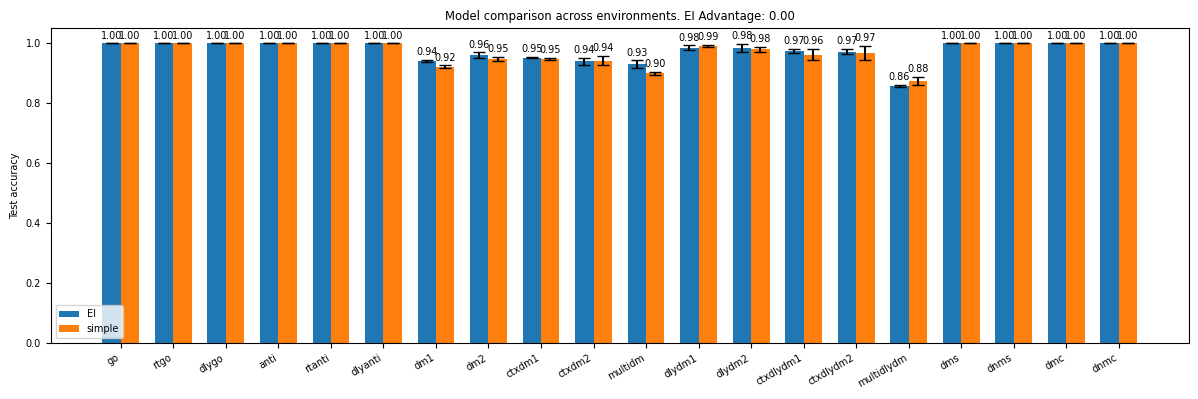

In [ ]:
env_names = [e_i.spec.id for e_i in env.envs]
env_names = [x.split('yang19.')[1].split('-v0')[0] for x in env_names]
print(env_names)
plot_test_performance(test_EI_performance_new, test_simple_performance_new,
                      env_names, show_values=True)

In [12]:
from net.colei import ColEI
from net.dann import DANN
from net.simple import SimpleNet
from net.eisep import EISepNet
from net.common import init_model

# def multiple_train(lr_ei, lr_simple, wd_ei, wd_simple, epochs, n_seed, hidden_size, lyapunov_every):
# lr_all = [1e-4, 1e-3, 1e-2, 1e-1]
# test_dict = []

def multiple_train(lr_ei, lr_simple, wd_ei, wd_simple, epochs=2000, n_seed=5, lyapunov_every=100):
    test_EI_performance = np.zeros((n_seed, len(env.envs)))
    test_simple_performance = np.zeros((n_seed, len(env.envs)))
    loss_log_ei = np.zeros((n_seed, epochs, 3))
    loss_log_simple = np.zeros((n_seed, epochs, 3))

    gradient_log_ei = np.zeros((n_seed, epochs, 1))
    gradient_log_simple = np.zeros((n_seed, epochs, 1))

    spectral_radius_log_ei = np.zeros((n_seed, epochs, 1))
    spectral_radius_log_simple = np.zeros((n_seed, epochs, 1))

    rec_balance_log_ei = np.zeros((n_seed, epochs, seq_len))
    rec_balance_log_simple = np.zeros((n_seed, epochs, seq_len))

    hidden_size = 64

    lyapunov_spectrum_log_ei = np.zeros((n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for EI
    lyapunov_spectrum_log_simple = np.zeros((n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for simple

    for seed in range(n_seed):
        print(f"Seed {seed + 1}/{n_seed}")
        torch.manual_seed(seed+10)
        np.random.seed(seed+10)

        # Create the model

        net = EISepNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size, entropy_loss=True).to(device)
        simple_net = SimpleNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size).to(device)

        net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(net, epochs, lyapunov_every, lr=lr_ei, wd=wd_ei)
        loss_log_ei[seed, :, :] = loss_log
        gradient_log_ei[seed, :, :] = gradient_log
        spectral_radius_log_ei[seed, :, :] = spectral_radius_log
        rec_balance_log_ei[seed, :, :] = rec_balance_log
        lyapunov_spectrum_log_ei[seed, :, :] = lyanpunov_spectrum_log
        simple_net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(simple_net, epochs, lyapunov_every, lr=lr_simple, wd=wd_simple)
        loss_log_simple[seed, :, :] = loss_log
        gradient_log_simple[seed, :, :] = gradient_log
        spectral_radius_log_simple[seed, :, :] = spectral_radius_log
        rec_balance_log_simple[seed, :, :] = rec_balance_log
        lyapunov_spectrum_log_simple[seed, :, :] = lyanpunov_spectrum_log

        test_EI_performance[seed, :] = test(net)
        test_simple_performance[seed, :] = test(simple_net)
    return {'performance':{'ei': test_EI_performance, 'simple': test_simple_performance},
            'loss_log': {'ei': loss_log_ei, 'simple': loss_log_simple},
            'gradient_log': {'ei': gradient_log_ei, 'simple': gradient_log_simple},
            'spectral_radius_log': {'ei': spectral_radius_log_ei, 'simple': spectral_radius_log_simple},
            'rec_balance_log': {'ei': rec_balance_log_ei, 'simple': rec_balance_log_simple},
            'lyapunov_spectrum_log': {'ei': lyapunov_spectrum_log_ei, 'simple': lyapunov_spectrum_log_simple}}

In [13]:
n_seed = 5
epochs = 2000
lyapunov_every = epochs//20
hidden_size = 64
wd_ei = 0
wd_simple = 0
test_dict = []
lr_all = [1e-4, 1e-3, 1e-2, 1e-1]
import pickle

In [ ]:
lr = lr_all[0]
print(f"Training EI with lr {lr}, simple with lr {lr}")
result = multiple_train(lr_ei=lr, lr_simple=lr, wd_ei=wd_ei, wd_simple=wd_simple,
                        epochs=epochs, n_seed=n_seed, lyapunov_every=lyapunov_every)
test_dict.append({'lr': lr, 'result': result})
pickle.dump(test_dict, open(f'./output/multitask/yang19_lr_comparison.pkl', 'wb'))

Training EI with lr 0.0001, simple with lr 0.0001
Seed 1/5
Epoch [0/2000], Loss: 1.9656
Epoch [100/2000], Loss: 1.7869
Epoch [200/2000], Loss: 1.7402
Epoch [300/2000], Loss: 1.7407
Epoch [400/2000], Loss: 1.7145
Epoch [500/2000], Loss: 1.7089
Epoch [600/2000], Loss: 1.7114
Epoch [700/2000], Loss: 1.6915
Epoch [800/2000], Loss: 1.6845
Epoch [900/2000], Loss: 1.6801
Epoch [1000/2000], Loss: 1.6806
Epoch [1100/2000], Loss: 1.6657
Epoch [1200/2000], Loss: 1.6455
Epoch [1300/2000], Loss: 1.6421
Epoch [1400/2000], Loss: 1.6144
Epoch [1500/2000], Loss: 1.6187
Epoch [1600/2000], Loss: 1.6212
Epoch [1700/2000], Loss: 1.5970
Epoch [1800/2000], Loss: 1.5643
Epoch [1900/2000], Loss: 1.5721
Finished Training
Epoch [0/2000], Loss: 1.4531
Epoch [100/2000], Loss: 1.0669
Epoch [200/2000], Loss: 1.0549
Epoch [300/2000], Loss: 1.0467
Epoch [400/2000], Loss: 1.0127
Epoch [500/2000], Loss: 1.0120
Epoch [600/2000], Loss: 0.9967
Epoch [700/2000], Loss: 0.9693
Epoch [800/2000], Loss: 0.9402
Epoch [900/2000], 

KeyboardInterrupt: 

In [ ]:
lr = lr_all[1]
print(f"Training EI with lr {lr}, simple with lr {lr}")
result = multiple_train(lr_ei=lr, lr_simple=lr, wd_ei=wd_ei, wd_simple=wd_simple,
                        epochs=epochs, n_seed=n_seed, lyapunov_every=lyapunov_every)
test_dict.append({'lr': lr, 'result': result})
pickle.dump(test_dict, open(f'./output/multitask/yang19_lr_comparison.pkl', 'wb'))

In [ ]:
lr = lr_all[2]
print(f"Training EI with lr {lr}, simple with lr {lr}")
result = multiple_train(lr_ei=lr, lr_simple=lr, wd_ei=wd_ei, wd_simple=wd_simple,
                        epochs=epochs, n_seed=n_seed, lyapunov_every=lyapunov_every)
test_dict.append({'lr': lr, 'result': result})
pickle.dump(test_dict, open(f'./output/multitask/yang19_lr_comparison.pkl', 'wb'))

Training EI with lr 0.01, simple with lr 0.01
Seed 1/5
Epoch [0/2000], Loss: 1.9740
Epoch [100/2000], Loss: 1.1293
Epoch [200/2000], Loss: 0.7119
Epoch [300/2000], Loss: 0.3923
Epoch [400/2000], Loss: 0.3386
Epoch [500/2000], Loss: 0.1698
Epoch [600/2000], Loss: 0.1104
Epoch [700/2000], Loss: 0.1540
Epoch [800/2000], Loss: 0.1272
Epoch [900/2000], Loss: 0.0810
Epoch [1000/2000], Loss: 0.0808
Epoch [1100/2000], Loss: 0.0730
Epoch [1200/2000], Loss: 0.0654
Epoch [1300/2000], Loss: 0.1142
Epoch [1400/2000], Loss: 0.0673
Epoch [1500/2000], Loss: 0.0296
Epoch [1600/2000], Loss: 0.0493
Epoch [1700/2000], Loss: 0.0583
Epoch [1800/2000], Loss: 0.0353
Epoch [1900/2000], Loss: 0.0376
Finished Training
Epoch [0/2000], Loss: 1.4645
Epoch [100/2000], Loss: 0.6966
Epoch [200/2000], Loss: 0.5038
Epoch [300/2000], Loss: 0.1979
Epoch [400/2000], Loss: 0.1492
Epoch [500/2000], Loss: 0.1306
Epoch [600/2000], Loss: 0.1786
Epoch [700/2000], Loss: 0.1161
Epoch [800/2000], Loss: 0.1330
Epoch [900/2000], Loss

KeyboardInterrupt: 

In [ ]:
lr = lr_all[3]
print(f"Training EI with lr {lr}, simple with lr {lr}")
result = multiple_train(lr_ei=lr, lr_simple=lr, wd_ei=wd_ei, wd_simple=wd_simple,
                        epochs=epochs, n_seed=n_seed, lyapunov_every=lyapunov_every)
test_dict.append({'lr': lr, 'result': result})
pickle.dump(test_dict, open(f'./output/multitask/yang19_lr_comparison.pkl', 'wb'))

FileNotFoundError: [Errno 2] No such file or directory: './output/multitask/yang19_lr_comparison.pkl'

In [ ]:
print(test_dict)

In [ ]:
env_names = [e_i.spec.id for e_i in env.envs]
env_names = [x.split('yang19.')[1].split('-v0')[0] for x in env_names]
print(env_names)

['go', 'rtgo', 'dlygo', 'anti', 'rtanti', 'dlyanti', 'dm1', 'dm2', 'ctxdm1', 'ctxdm2', 'multidm', 'dlydm1', 'dlydm2', 'ctxdlydm1', 'ctxdlydm2', 'multidlydm', 'dms', 'dnms', 'dmc', 'dnmc']


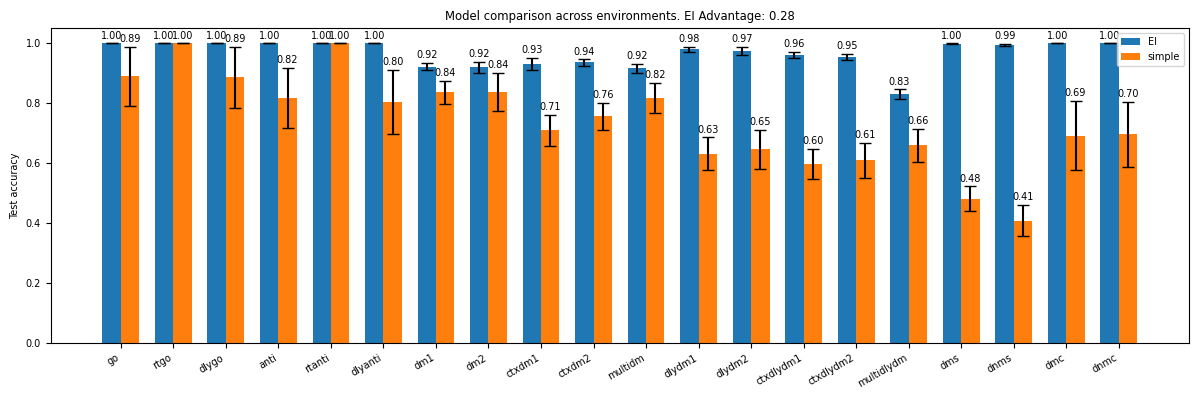

In [ ]:
plot_test_performance(test_EI_performance, test_simple_performance,
                      env_names, show_values=True)

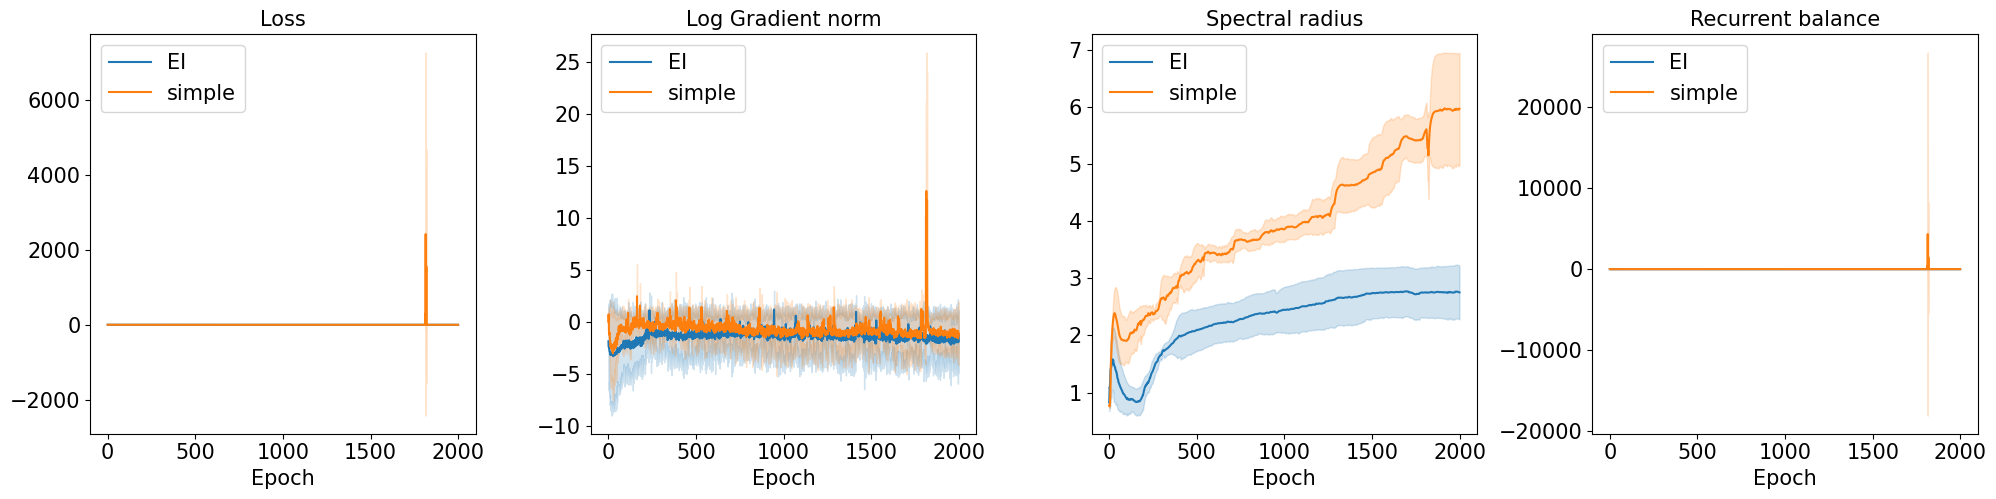

In [ ]:
plot_loss_curve(loss_log_ei, gradient_log_ei,
                loss_log_simple, gradient_log_simple,
                spectral_radius_log_ei, spectral_radius_log_simple,
                rec_balance_log_ei, rec_balance_log_simple)

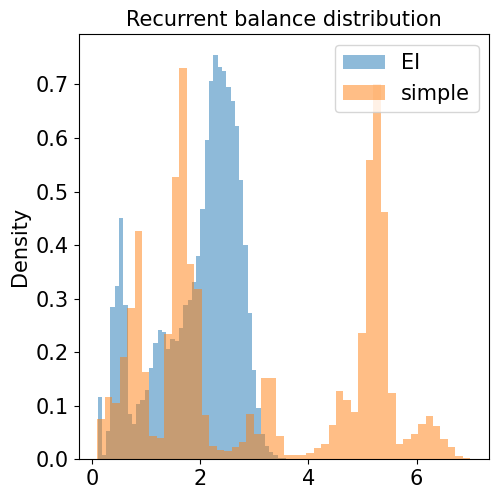

In [ ]:
fontsize = 15
rec_balance_log_ei_ = rec_balance_log_ei.mean(0)
rec_balance_log_simple_ = rec_balance_log_simple.mean(0)
fig, ax = plt.subplots(1,1, figsize=(5, 5))
ax.hist(rec_balance_log_ei_.flatten(), bins=50, alpha=0.5, label='EI', density=True)
ax.hist(rec_balance_log_simple_.flatten(), bins=50, alpha=0.5, label='simple', density=True)
# ax.set_xlabel('Recurrent balance')
ax.set_ylabel('Density', fontsize=fontsize)
ax.set_title('Recurrent balance distribution', fontsize=fontsize)
ax.legend(fontsize=fontsize)
ax.tick_params(labelsize=fontsize)
plt.tight_layout()

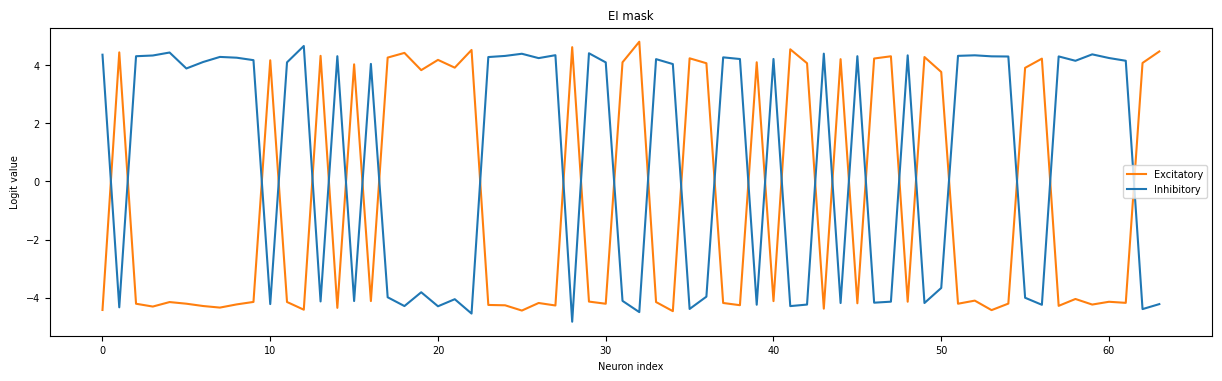

In [ ]:
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
ei_code = np.where(eimask[:, 0] > eimask[:, 1], 1., -1.)
mask = np.where(ei_code.reshape(-1,1)>0, np.array([[1,0]]).repeat(eimask.shape[0], axis=0),
                np.array([[0,1]]).repeat(eimask.shape[0], axis=0))
fig, ax = plt.subplots(1,1,figsize=(15, 4))
ax.plot(eimask[:, 0], label='Excitatory', color='C1')
ax.plot(eimask[:, 1], label='Inhibitory', color='C0')
ax.set_title('EI mask')
ax.set_xlabel('Neuron index')
ax.set_ylabel('Logit value')
ax.legend()
plt.show()

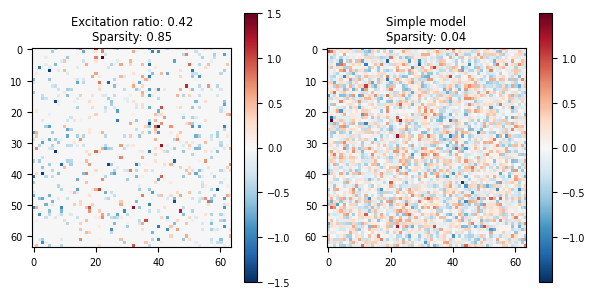

In [ ]:
weight = net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
limit = 1.5
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nSparsity: {sparsity:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
limit = (np.max(weight_simple)+np.max(-weight_simple))/2
im = ax[1].imshow(weight_simple, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity_simple = 1 - np.mean(np.abs(weight_simple)>0.1*np.std(np.abs(weight_simple)))
ax[1].set_title(f'Simple model\nSparsity: {sparsity_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()


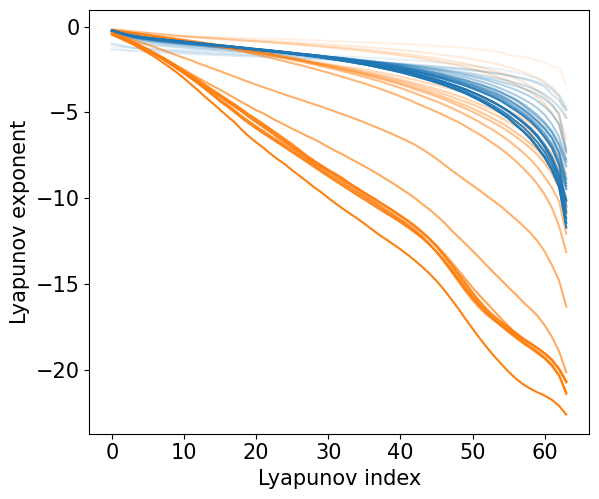

In [ ]:
plot_lyapunov_spectrum(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple)

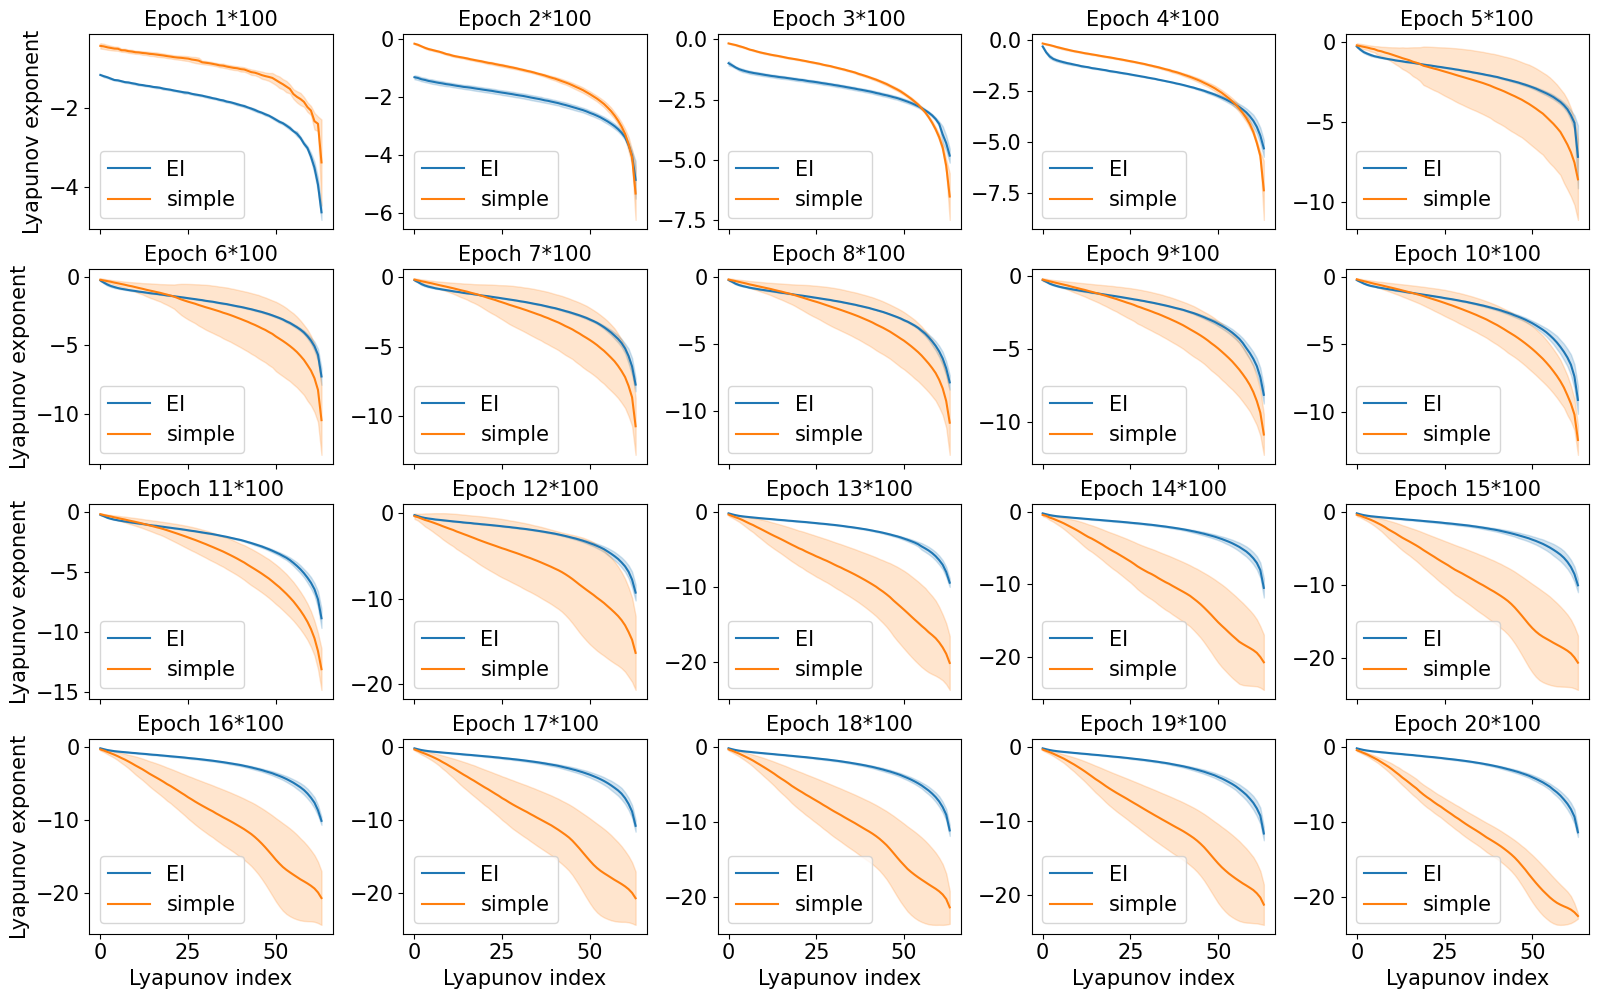

In [ ]:
plot_lyapunov_spectrum_separately(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple, lyapunov_every)

In [ ]:
# torch.save(net.state_dict(), './model/multitask/yang19_ei_softplus.pth')
# torch.save(simple_net.state_dict(), './model/multitask/yang19_simple_tanh.pth')

In [ ]:
# from pdm_model import Net, SimpleNet
# device = 'cuda:0'
# batch_size = 64
# hidden_size = 64
# net = Net(ob_size=ob_size, num_h=hidden_size, act_size=act_size, entropy_loss=True).to(device)
# simple_net = SimpleNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size).to(device)
# net_path = './model/multitask/yang19_ei_softplus.pth'
# simple_net_path = './model/multitask/yang19_simple_tanh.pth'
# net.load_state_dict(torch.load(net_path))
# simple_net.load_state_dict(torch.load(simple_net_path))

In [ ]:
n_test = 10
def plot_activity(hidden_size, net, color):
    net.eval()
    fig, ax = plt.subplots((hidden_size-1)//8+1, 8, figsize=(32, (hidden_size//8+1)*3))
    ax = ax.flatten()
    inputs, targets = dataset()
    inputs = torch.from_numpy(inputs).float().to(device)
    targets = torch.from_numpy(targets).long().to(device)

    outputs, eimask_logit, hidden = net(inputs)
    # print('hidden', hidden.shape)
    h_all = hidden[0].detach().cpu().numpy()
    h_all_mean = h_all.mean(1)
    h_all_std = h_all.std(1)
    for j in range(hidden_size):
        ax[j].plot(h_all_mean[:,j], color=color)
        ax[j].fill_between(np.arange(seq_len), h_all_mean[:,j]-h_all_std[:,j], h_all_mean[:,j]+h_all_std[:,j],
                           alpha=0.2, color=color)
    normalized_variance = (h_all_std/(h_all.max((0,1))-h_all.min((0,1)))).mean()
    # normalized_variance = h_all_std.mean()

    plt.suptitle(f'Normalized variance: {normalized_variance:.4f}', fontsize=30)
    plt.tight_layout()
    plt.show()
    plt.close()


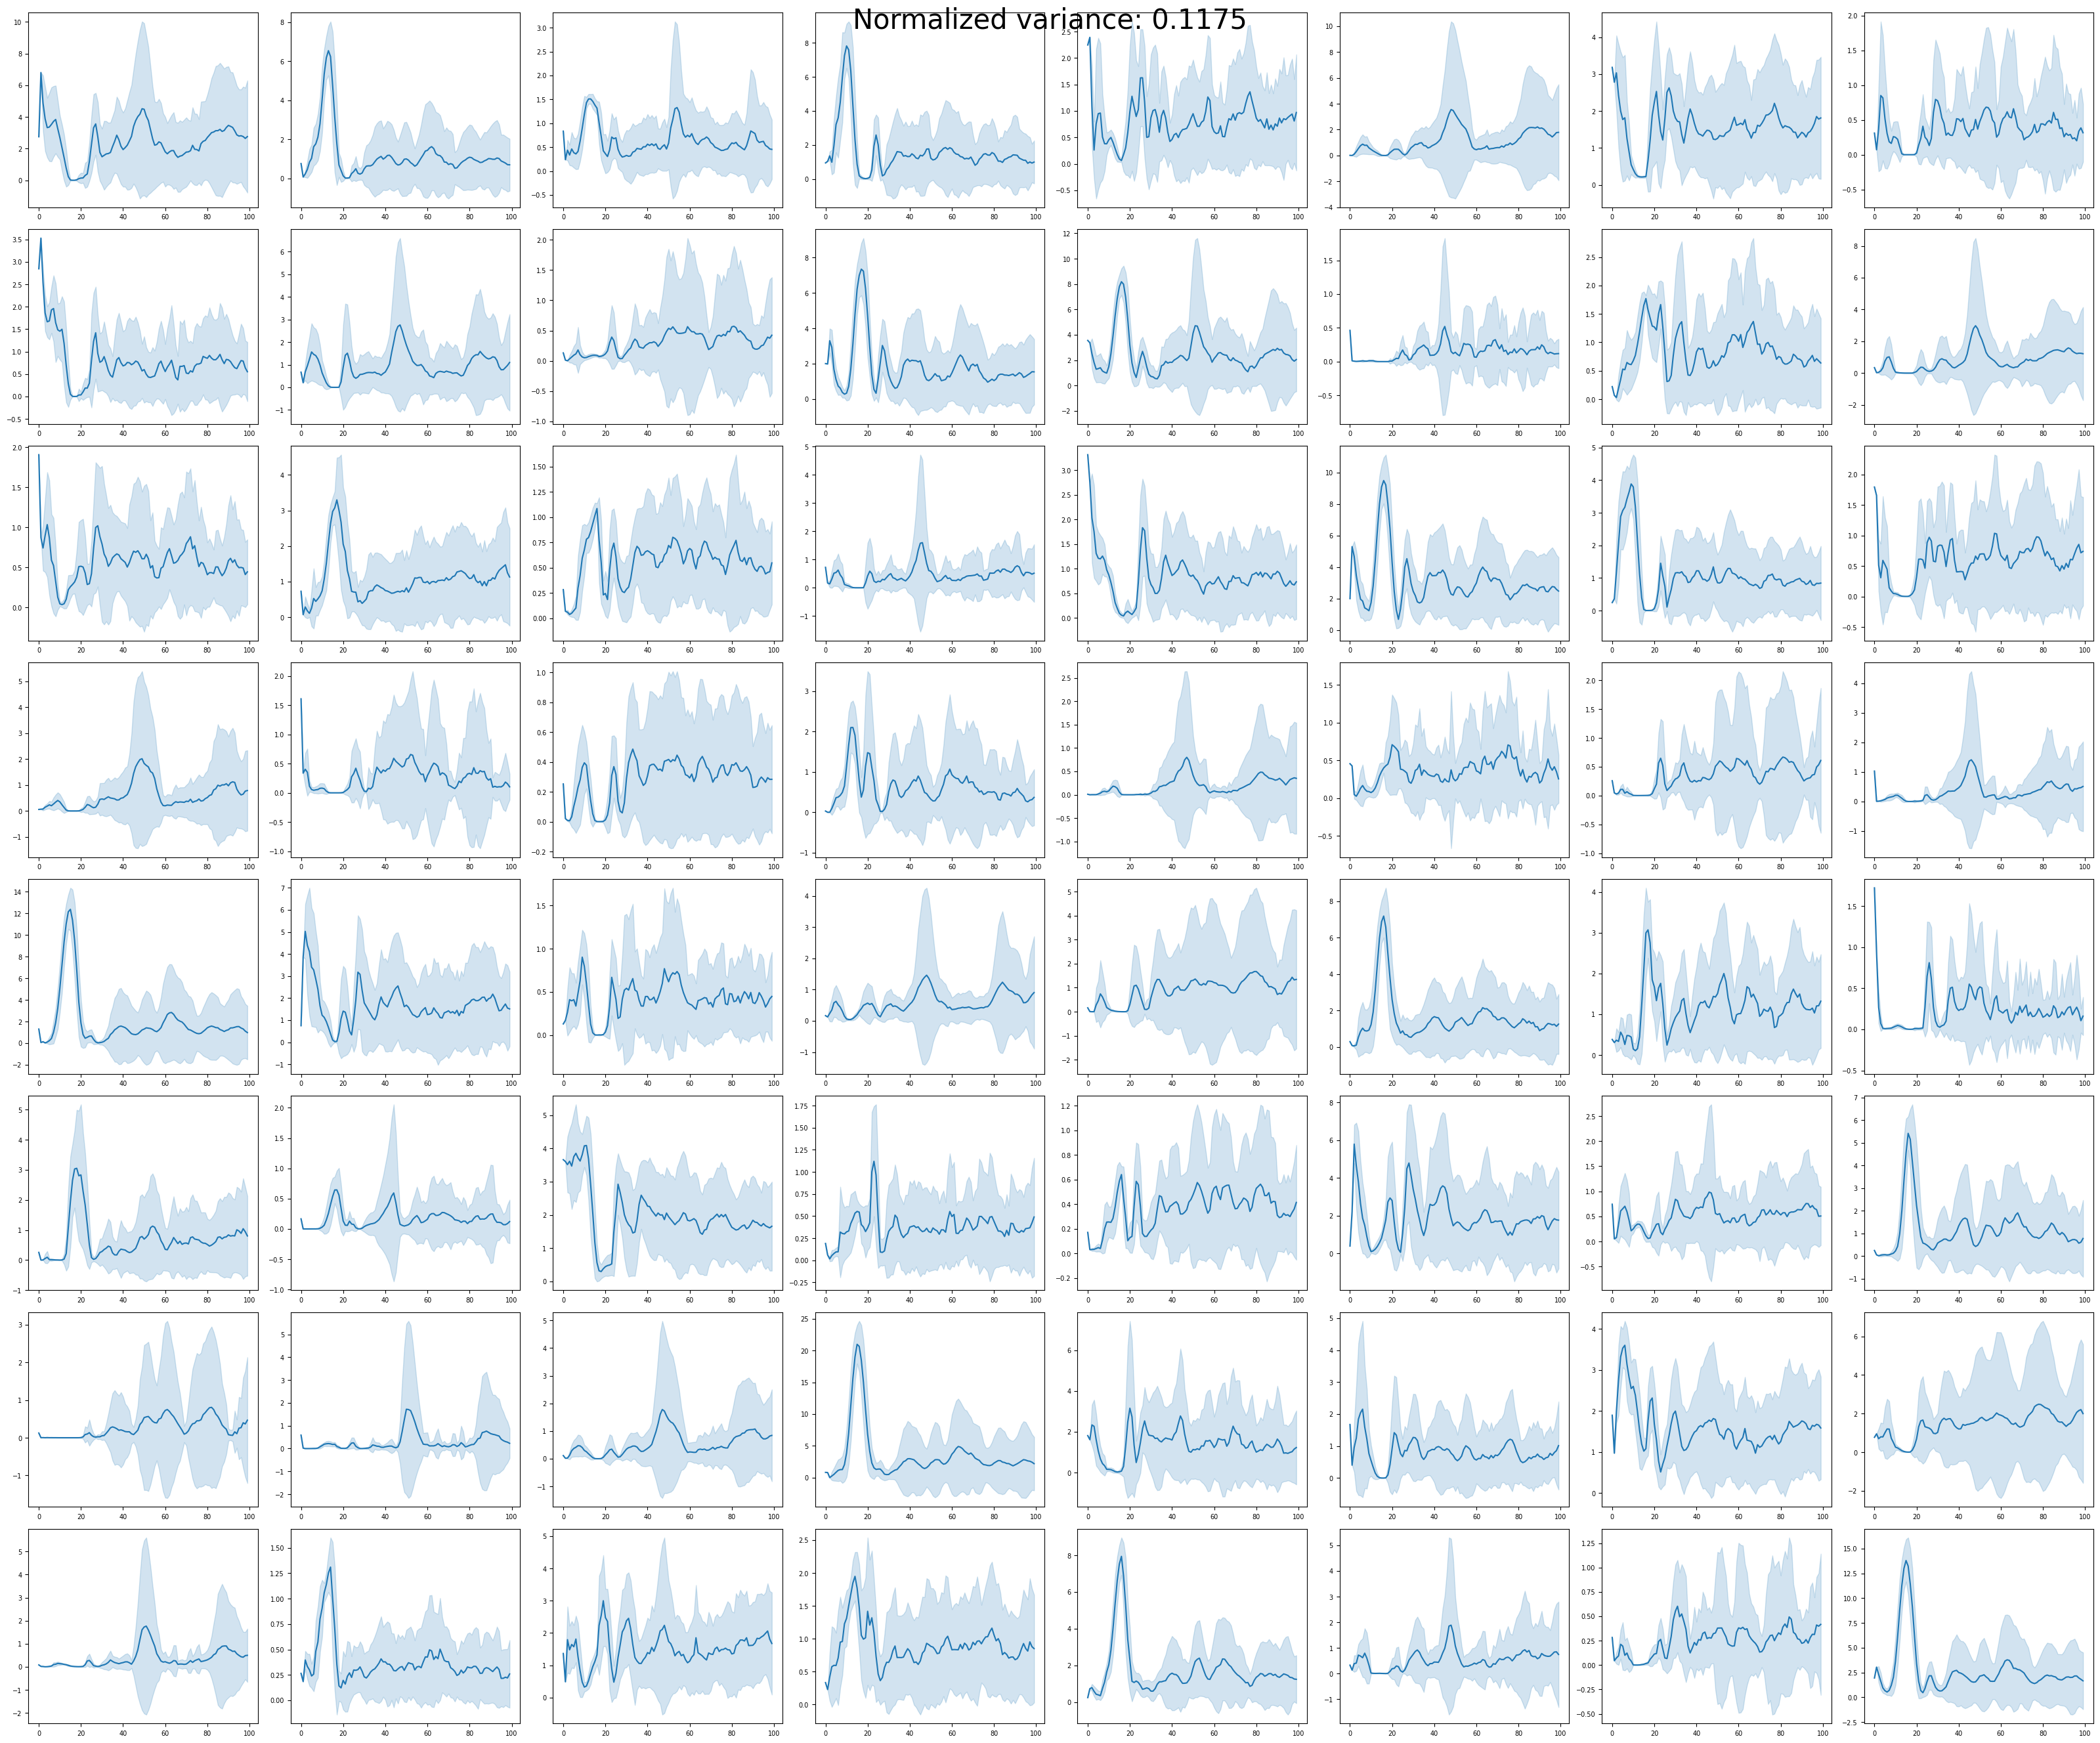

In [ ]:
plot_activity(hidden_size, net, 'C0')

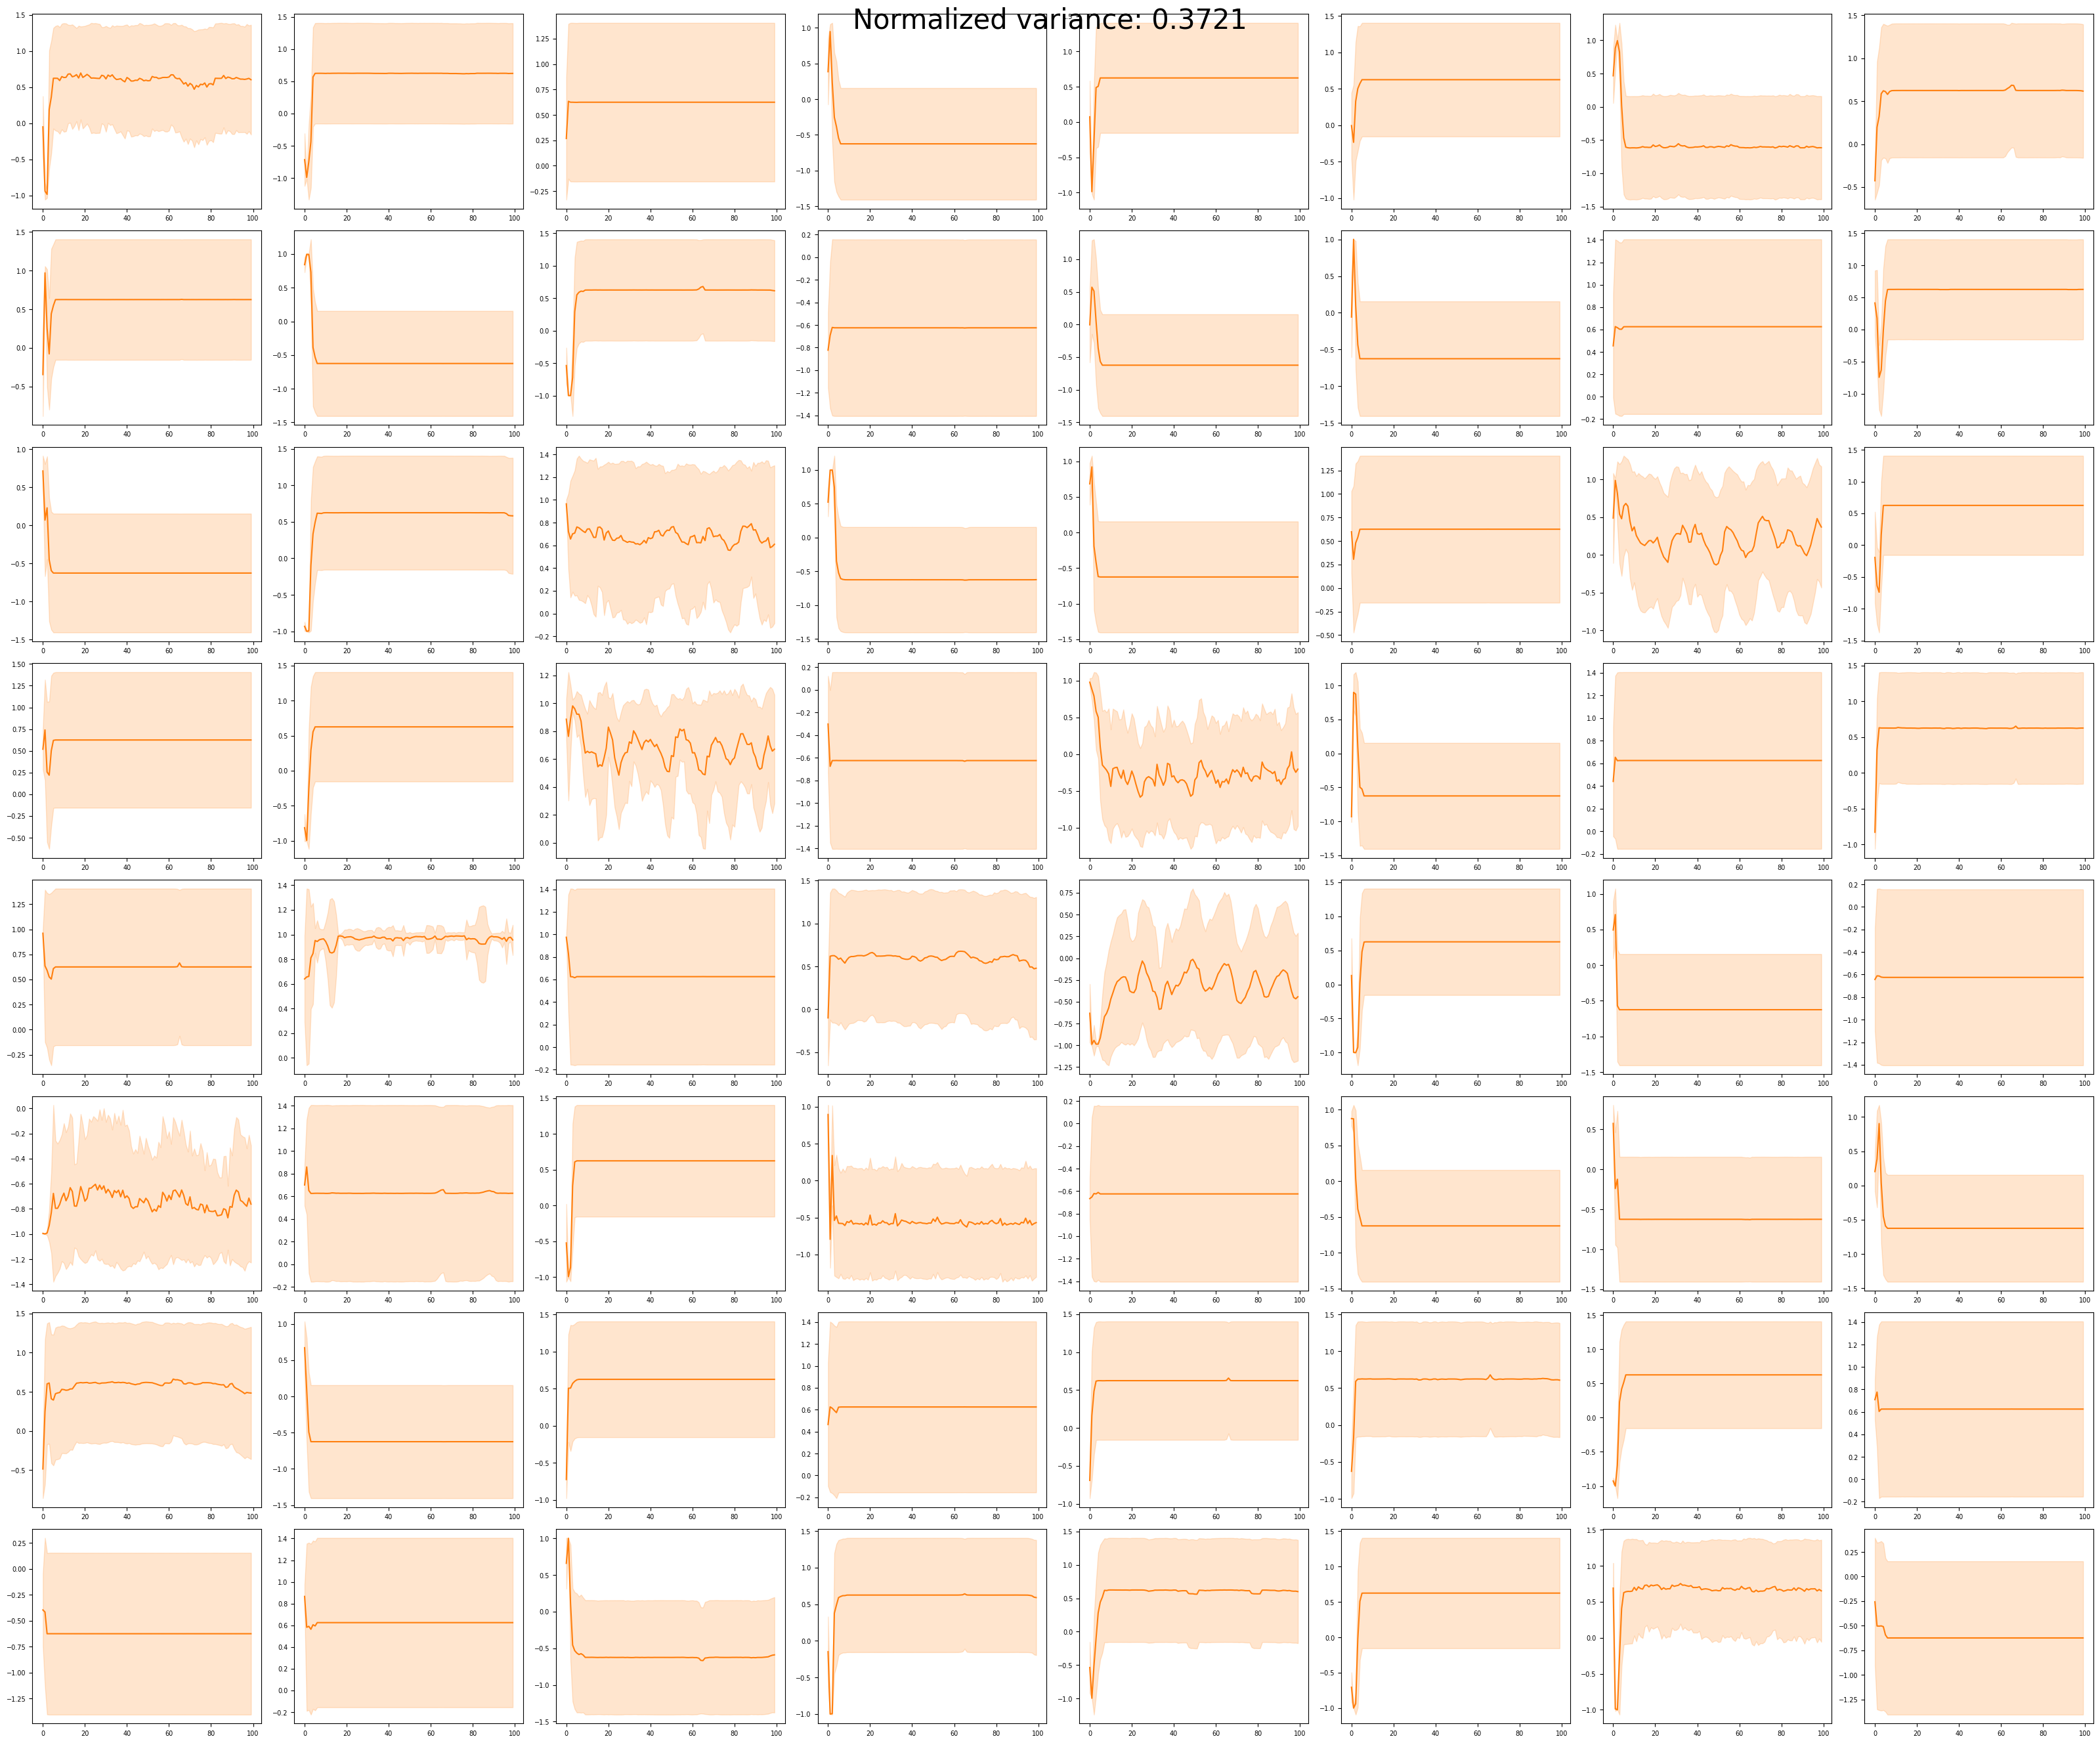

In [ ]:
plot_activity(hidden_size, simple_net, 'C1')